# Online Food Delivery Analysis

Step 1: Data Collection

In [1]:
import pandas as pd
from pathlib import Path
from pprint import pprint

# Use the original CSV as the source
file_path = Path(r"C:\Users\Admin\Project\Online Food Delivery Analysis\ONINE_FOOD_DELIVERY_ANALYSIS.csv")

df_raw = pd.read_csv(file_path)

# Create a copy of the raw DataFrame to work with
df_clean = df_raw.copy()

Step 2 Data Understanding

In [2]:
# Check the number of rows and columns
print("Shape:", df_clean.shape)

Shape: (100000, 25)


In [3]:
# Check column names
print("\nColumns:")
pprint(df_clean.columns.tolist())


Columns:
['Order_ID',
 'Customer_ID',
 'Customer_Age',
 'Customer_Gender',
 'City',
 'Area',
 'Restaurant_ID',
 'Restaurant_Name',
 'Cuisine_Type',
 'Order_Date',
 'Order_Time',
 'Delivery_Time_Min',
 'Distance_km',
 'Order_Value',
 'Discount_Applied',
 'Final_Amount',
 'Payment_Mode',
 'Order_Status',
 'Cancellation_Reason',
 'Delivery_Partner_ID',
 'Delivery_Rating',
 'Restaurant_Rating',
 'Order_Day',
 'Peak_Hour',
 'Profit_Margin']


In [4]:
# Check data types and non-null counts
print("\nDataFrame Info:")
print(df_clean.info())


DataFrame Info:
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 25 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   Order_ID             100000 non-null  str    
 1   Customer_ID          100000 non-null  str    
 2   Customer_Age         49907 non-null   float64
 3   Customer_Gender      75144 non-null   str    
 4   City                 83274 non-null   str    
 5   Area                 83315 non-null   str    
 6   Restaurant_ID        100000 non-null  str    
 7   Restaurant_Name      100000 non-null  str    
 8   Cuisine_Type         83115 non-null   str    
 9   Order_Date           98986 non-null   str    
 10  Order_Time           98002 non-null   str    
 11  Delivery_Time_Min    66641 non-null   float64
 12  Distance_km          66530 non-null   float64
 13  Order_Value          66673 non-null   float64
 14  Discount_Applied     83285 non-null   float64
 15  Final_Amount

In [5]:
# Find the numerical summary
print("\nNumerical Summary:")
print(df_clean.describe())


Numerical Summary:
       Customer_Age  Delivery_Time_Min   Distance_km   Order_Value  \
count  49907.000000       66641.000000  66530.000000  66673.000000   
mean      38.976516         127.475923     16.449242   2081.830126   
std       12.372157          90.805839     12.256742   1553.628891   
min       18.000000          20.000000      1.000000    150.000000   
25%       28.000000          45.000000      5.470000    673.000000   
50%       39.000000         120.000000      9.970000   1197.000000   
75%       50.000000         210.000000     27.430000   3494.000000   
max       60.000000         300.000000     40.000000   5000.000000   

       Discount_Applied  Final_Amount  Delivery_Rating  Restaurant_Rating  \
count      83285.000000  44303.000000     83477.000000      100000.000000   
mean          93.936243   1961.101190         2.991531           4.249680   
std          108.209904   1557.354417         1.414108           0.722554   
min            0.000000   -150.000000    

Step 3: Data Cleaning & Preprocessing

In [6]:
# Check the missing values
print("\nMissing values:")
print(df_clean.isna().sum())


Missing values:
Order_ID                   0
Customer_ID                0
Customer_Age           50093
Customer_Gender        24856
City                   16726
Area                   16685
Restaurant_ID              0
Restaurant_Name            0
Cuisine_Type           16885
Order_Date              1014
Order_Time              1998
Delivery_Time_Min      33359
Distance_km            33470
Order_Value            33327
Discount_Applied       16715
Final_Amount           55697
Payment_Mode           19911
Order_Status               0
Cancellation_Reason    90969
Delivery_Partner_ID        0
Delivery_Rating        16523
Restaurant_Rating          0
Order_Day                  0
Peak_Hour              32962
Profit_Margin              0
dtype: int64


Checking missing count and missing percentage

In [7]:
missing_summary = pd.DataFrame({
    "missing_count": df_clean.isna().sum(),
    "missing_percent": (df_clean.isna().mean() * 100).round(2)
})

print("Missing values by column:")
print(
    missing_summary[missing_summary["missing_count"] > 0]
    .sort_values("missing_count", ascending=False)
)

print("\nRows by order status:")
print(df_clean["Order_Status"].value_counts(dropna=False))

print("\nCancellation reasons by order status:")
print(pd.crosstab(
    df_clean["Order_Status"],
    df_clean["Cancellation_Reason"],
    margins=True,
    dropna=False
))

Missing values by column:
                     missing_count  missing_percent
Cancellation_Reason          90969            90.97
Final_Amount                 55697            55.70
Customer_Age                 50093            50.09
Distance_km                  33470            33.47
Delivery_Time_Min            33359            33.36
Order_Value                  33327            33.33
Peak_Hour                    32962            32.96
Customer_Gender              24856            24.86
Payment_Mode                 19911            19.91
Cuisine_Type                 16885            16.89
City                         16726            16.73
Discount_Applied             16715            16.72
Area                         16685            16.68
Delivery_Rating              16523            16.52
Order_Time                    1998             2.00
Order_Date                    1014             1.01

Rows by order status:
Order_Status
Delivered    84964
Cancelled    15036
Name: count, dty

Checking missing values and missing percentage in order status

In [8]:
cols_to_check = [
    "Delivery_Time_Min",
    "Distance_km",
    "Order_Value",
    "Discount_Applied",
    "Final_Amount",
    "Delivery_Rating",
    "Cancellation_Reason",
]

grouped = df_clean.groupby("Order_Status")[cols_to_check]

print("Missing-value counts by order status:")
print(grouped.apply(lambda group: group.isna().sum()).T)

print("\nMissing-value percentages by order status:")
print((grouped.apply(lambda group: group.isna().mean() * 100).T).round(2))

Missing-value counts by order status:
Order_Status         Cancelled  Delivered
Delivery_Time_Min         5030      28329
Distance_km               5118      28352
Order_Value               5006      28321
Discount_Applied          2586      14129
Final_Amount              8325      47372
Delivery_Rating           2475      14048
Cancellation_Reason       6005      84964

Missing-value percentages by order status:
Order_Status         Cancelled  Delivered
Delivery_Time_Min        33.45      33.34
Distance_km              34.04      33.37
Order_Value              33.29      33.33
Discount_Applied         17.20      16.63
Final_Amount             55.37      55.76
Delivery_Rating          16.46      16.53
Cancellation_Reason      39.94     100.00


In [9]:
inputs_present = df_clean[["Order_Value", "Discount_Applied"]].notna().all(axis=1)
final_present = df_clean["Final_Amount"].notna()

print("Final_Amount missing despite both inputs being present:",
      int((inputs_present & ~final_present).sum()))

print("Final_Amount present despite at least one input being missing:",
      int((final_present & ~inputs_present).sum()))

check = df_clean.loc[
    inputs_present & final_present,
    ["Order_Value", "Discount_Applied", "Final_Amount"]
].copy()

difference = (
    check["Final_Amount"] - (check["Order_Value"] - check["Discount_Applied"])
).abs()

print("Rows where Final_Amount differs from Order_Value - Discount_Applied:",
      int((difference > 0.01).sum()))

print("\nExamples of differences:")
print(check.loc[difference > 0.01].head(10))

Final_Amount missing despite both inputs being present: 11211
Final_Amount present despite at least one input being missing: 0
Rows where Final_Amount differs from Order_Value - Discount_Applied: 0

Examples of differences:
Empty DataFrame
Columns: [Order_Value, Discount_Applied, Final_Amount]
Index: []


In [10]:
mask = (
    df_clean["Final_Amount"].isna()
    & df_clean["Order_Value"].notna()
    & df_clean["Discount_Applied"].notna()
)

df_clean.loc[mask, "Final_Amount"] = (
    df_clean.loc[mask, "Order_Value"]
    - df_clean.loc[mask, "Discount_Applied"]
)

print("Amounts filled:", mask.sum())
print("Missing amounts left:", df_clean["Final_Amount"].isna().sum())

Amounts filled: 11211
Missing amounts left: 44486


In [11]:
mask = df_clean["Restaurant_Rating"] > 5

print("Ratings above 5 before correction:", int(mask.sum()))

df_clean.loc[mask, "Restaurant_Rating"] = 5

print("Ratings above 5 after correction:",
      int((df_clean["Restaurant_Rating"] > 5).sum()))

Ratings above 5 before correction: 18019
Ratings above 5 after correction: 0


In [12]:
print("Original ratings above 5:",
      int((df_raw["Restaurant_Rating"] > 5).sum()))
print("Original maximum rating:",
      df_raw["Restaurant_Rating"].max())

print("Working-copy ratings above 5:",
      int((df_clean["Restaurant_Rating"] > 5).sum()))
print("Working-copy maximum rating:",
      df_clean["Restaurant_Rating"].max())

Original ratings above 5: 18019
Original maximum rating: 5.5
Working-copy ratings above 5: 0
Working-copy maximum rating: 5.0


In [13]:
mask = df_clean["Restaurant_Rating"] > 5
print("Ratings above 5 before correction:", int(mask.sum()))

df_clean.loc[mask, "Restaurant_Rating"] = 5

print("Ratings above 5 after correction:",
      int((df_clean["Restaurant_Rating"] > 5).sum()))

Ratings above 5 before correction: 0
Ratings above 5 after correction: 0


Numeric missing values: use the median for direct numeric fields.

In [14]:
numeric_columns = [
    "Customer_Age",
    "Delivery_Time_Min",
    "Distance_km",
    "Order_Value",
    "Discount_Applied",
    "Delivery_Rating",
]

for column in numeric_columns:
    df_clean[column] = df_clean[column].fillna(df_clean[column].median())

print("Missing values remaining in these numeric fields:")
print(df_clean[numeric_columns].isna().sum())

Missing values remaining in these numeric fields:
Customer_Age         0
Delivery_Time_Min    0
Distance_km          0
Order_Value          0
Discount_Applied     0
Delivery_Rating      0
dtype: int64


Categorical Values: Making as "Unknown" 

In [15]:
categorical_columns = [
    "Customer_Gender",
    "City",
    "Area",
    "Cuisine_Type",
    "Payment_Mode",
    "Peak_Hour",
]

for column in categorical_columns:
    mode_value = df_clean[column].mode(dropna=True).iloc[0]
    df_clean[column] = df_clean[column].fillna(mode_value)

# A cancellation reason does not apply to delivered orders
delivered_missing_reason = (
    (df_clean["Order_Status"] == "Delivered")
    & df_clean["Cancellation_Reason"].isna()
)
df_clean.loc[delivered_missing_reason, "Cancellation_Reason"] = "Not applicable"

# Some cancelled orders have no recorded reason
cancelled_missing_reason = (
    (df_clean["Order_Status"] == "Cancelled")
    & df_clean["Cancellation_Reason"].isna()
)
df_clean.loc[cancelled_missing_reason, "Cancellation_Reason"] = "Unknown"

print("Missing values remaining in these categorical fields:")
print(df_clean[categorical_columns].isna().sum())
print("\nMissing cancellation reasons:",
      int(df_clean["Cancellation_Reason"].isna().sum()))
print("\nCancellation reason categories:")
print(df_clean["Cancellation_Reason"].value_counts())

Missing values remaining in these categorical fields:
Customer_Gender    0
City               0
Area               0
Cuisine_Type       0
Payment_Mode       0
Peak_Hour          0
dtype: int64

Missing cancellation reasons: 0

Cancellation reason categories:
Cancellation_Reason
Not applicable        84964
Unknown                6005
Late Delivery          3059
Customer Cancelled     2993
Restaurant Issue       2979
Name: count, dtype: int64


Cleaning Final_Amount

In [16]:
mask = df_clean["Final_Amount"].isna()

df_clean.loc[mask, "Final_Amount"] = (
    df_clean.loc[mask, "Order_Value"]
    - df_clean.loc[mask, "Discount_Applied"]
)

print("Final amounts calculated:", int(mask.sum()))
print("Final amounts still missing:",
      int(df_clean["Final_Amount"].isna().sum()))

Final amounts calculated: 44486
Final amounts still missing: 0


Checking order date and order time

In [17]:
remaining_missing = df_clean.isna().sum()
print("Columns that still have missing values:")
print(remaining_missing[remaining_missing > 0])

print("\nOrder_Time values, including missing:")
print(df_clean["Order_Time"].value_counts(dropna=False).head())

Columns that still have missing values:
Order_Date    1014
Order_Time    1998
dtype: int64

Order_Time values, including missing:
Order_Time
0:00    98002
NaN      1998
Name: count, dtype: int64


3.2 Removing or capping outliers (delivery time, order value)

In [18]:
for column in ["Delivery_Time_Min", "Order_Value"]:
    q1 = df_clean[column].quantile(0.25)
    q3 = df_clean[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = df_clean[column].notna() & ~df_clean[column].between(lower, upper)

    print(f"\n{column}")
    print(f"IQR bounds: {lower:.1f} to {upper:.1f}")
    print(f"Outlier count: {int(outliers.sum())}")


Delivery_Time_Min
IQR bounds: -102.5 to 325.5
Outlier count: 0

Order_Value
IQR bounds: -1777.0 to 5455.0
Outlier count: 0


3.3 Correcting invalid values (ratings > 5, negative profit margin)


In [19]:
print("Restaurant ratings outside 1-5:",
      int(((df_clean["Restaurant_Rating"] < 1) |
           (df_clean["Restaurant_Rating"] > 5)).sum()))

print("Delivery ratings outside 1-5:",
      int(((df_clean["Delivery_Rating"] < 1) |
           (df_clean["Delivery_Rating"] > 5)).sum()))

print("\nProfit margin minimum:", df_clean["Profit_Margin"].min())
print("Profit margin maximum:", df_clean["Profit_Margin"].max())
print("Negative profit margin rows:",
      int((df_clean["Profit_Margin"] < 0).sum()))

Restaurant ratings outside 1-5: 0
Delivery ratings outside 1-5: 0

Profit margin minimum: -0.2
Profit margin maximum: 0.5
Negative profit margin rows: 27733


3.4 Standardizing categorical values


In [20]:
categorical_columns = [
    "Customer_Gender",
    "City",
    "Area",
    "Cuisine_Type",
    "Payment_Mode",
    "Order_Status",
    "Cancellation_Reason",
]

for column in categorical_columns:
    values = sorted(df_clean[column].dropna().astype(str).unique())
    print(f"{column}: {values}")

Customer_Gender: ['Female', 'Male', 'Other']
City: ['Bangalore', 'Chennai', 'Delhi', 'Hyderabad', 'Mumbai']
Area: ['Central', 'East', 'North', 'South', 'West']
Cuisine_Type: ['Arabian', 'Chinese', 'Indian', 'Italian', 'Mexican']
Payment_Mode: ['COD', 'Card', 'UPI', 'Wallet']
Order_Status: ['Cancelled', 'Delivered']
Cancellation_Reason: ['Customer Cancelled', 'Late Delivery', 'Not applicable', 'Restaurant Issue', 'Unknown']


3.5 Ensuring logical consistency (e.g., cancelled orders vs ratings)


In [21]:
print("Original delivery-rating summary by order status:")
print(
    df_raw.groupby("Order_Status")["Delivery_Rating"]
    .agg(["count", "mean", "min", "max"])
)

print("\nCancelled orders with a rating:")
print(
    int(
        (
            (df_raw["Order_Status"] == "Cancelled")
            & df_raw["Delivery_Rating"].notna()
        ).sum()
    )
)

Original delivery-rating summary by order status:
              count      mean  min  max
Order_Status                           
Cancelled     12561  2.989252  1.0  5.0
Delivered     70916  2.991934  1.0  5.0

Cancelled orders with a rating:
12561


Converting the CSV file after cleaning and Save locally for backup

In [22]:
output_path = file_path.with_name("online_food_delivery_clean_new.csv")
df_clean.to_csv(output_path, index=False)

print("Saved to:", output_path)

Saved to: C:\Users\Admin\Project\Online Food Delivery Analysis\online_food_delivery_clean_new.csv


In [23]:
display(df_clean.head(10))

,Order_ID,Customer_ID,Customer_Age,Customer_Gender,City,Area,Restaurant_ID,Restaurant_Name,Cuisine_Type,Order_Date,...,Final_Amount,Payment_Mode,Order_Status,Cancellation_Reason,Delivery_Partner_ID,Delivery_Rating,Restaurant_Rating,Order_Day,Peak_Hour,Profit_Margin
0,ORD000001,CUST6948,19.0,Male,Hyderabad,Central,RES936,Restaurant_29,Chinese,10/20/2024,...,1147.0,UPI,Delivered,Not applicable,DP563,5.0,4.4,Weekend,True,0.13
1,ORD000002,CUST6515,39.0,Female,Chennai,North,RES689,Restaurant_419,Chinese,8/12/2024,...,4849.0,COD,Delivered,Not applicable,DP369,5.0,4.7,Weekday,True,0.48
2,ORD000003,CUST1765,39.0,Male,Delhi,South,RES723,Restaurant_244,Arabian,12/8/2024,...,737.0,Wallet,Delivered,Not applicable,DP580,4.0,4.9,Weekend,True,0.08
3,ORD000004,CUST2744,39.0,Male,Mumbai,Central,RES951,Restaurant_178,Chinese,10/8/2024,...,1147.0,UPI,Cancelled,Late Delivery,DP155,2.0,3.4,Weekday,False,0.04
4,ORD000005,CUST4389,57.0,Female,Chennai,South,RES419,Restaurant_262,Chinese,2/4/2024,...,352.0,Card,Delivered,Not applicable,DP728,2.0,4.4,Weekend,False,0.12
5,ORD000006,CUST3161,37.0,Other,Chennai,East,RES810,Restaurant_153,Mexican,7/9/2024,...,897.0,Card,Delivered,Not applicable,DP119,3.0,4.6,Weekday,True,0.24
6,ORD000007,CUST2307,40.0,Other,Delhi,South,RES333,Restaurant_302,Chinese,2/14/2024,...,1197.0,UPI,Delivered,Not applicable,DP624,2.0,4.5,Weekday,False,0.02
7,ORD000008,CUST5865,39.0,Male,Hyderabad,North,RES696,Restaurant_41,Chinese,5/26/2024,...,3486.0,UPI,Delivered,Not applicable,DP316,5.0,3.8,Weekend,False,0.18
8,ORD000009,CUST4356,39.0,Other,Delhi,Central,RES780,Restaurant_155,Italian,9/7/2024,...,425.0,Card,Delivered,Not applicable,DP531,2.0,3.7,Weekend,True,0.08
9,ORD000010,CUST2404,39.0,Female,Hyderabad,South,RES155,Restaurant_368,Chinese,1/22/2024,...,4641.0,Card,Delivered,Not applicable,DP338,4.0,4.5,Weekday,True,0.03


Step 4: Exploratory Data Analysis (EDA)


4.1 Distribution of order values and delivery time


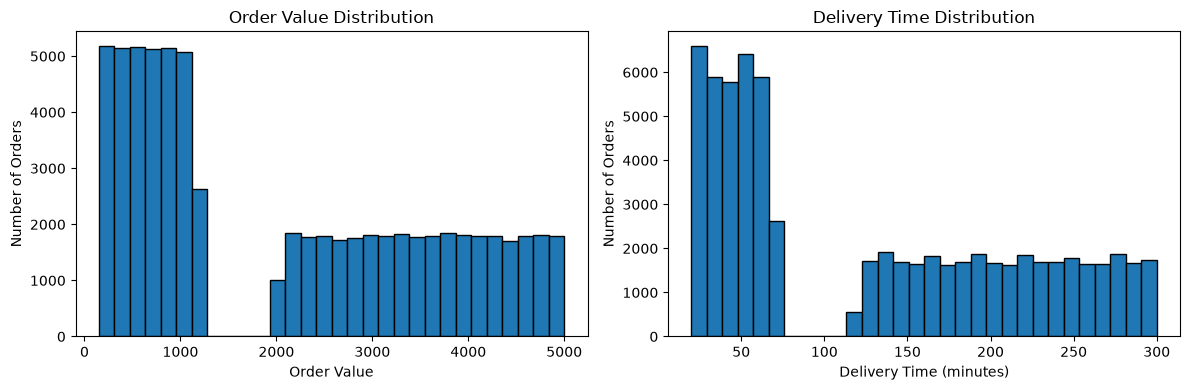

In [24]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df_raw["Order_Value"].dropna(), bins=30, edgecolor="black")
axes[0].set_title("Order Value Distribution")
axes[0].set_xlabel("Order Value")
axes[0].set_ylabel("Number of Orders")

axes[1].hist(df_raw["Delivery_Time_Min"].dropna(), bins=30, edgecolor="black")
axes[1].set_title("Delivery Time Distribution")
axes[1].set_xlabel("Delivery Time (minutes)")
axes[1].set_ylabel("Number of Orders")

plt.tight_layout()
plt.show()

4.2 City-wise and cuisine-wise order analysis


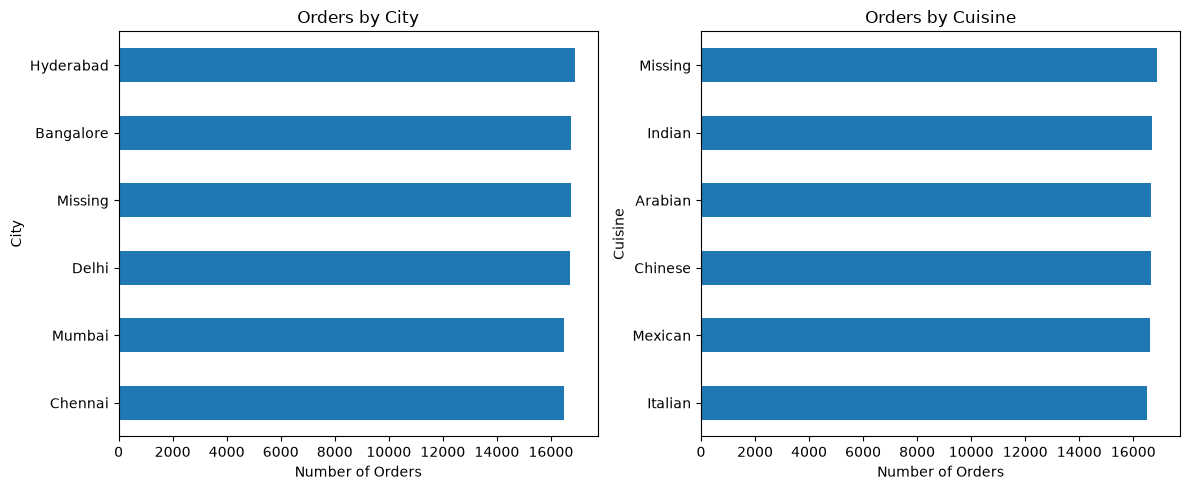

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

city_counts = df_raw["City"].fillna("Missing").value_counts().sort_values()
city_counts.plot(kind="barh", ax=axes[0])
axes[0].set_title("Orders by City")
axes[0].set_xlabel("Number of Orders")
axes[0].set_ylabel("City")

cuisine_counts = df_raw["Cuisine_Type"].fillna("Missing").value_counts().sort_values()
cuisine_counts.plot(kind="barh", ax=axes[1])
axes[1].set_title("Orders by Cuisine")
axes[1].set_xlabel("Number of Orders")
axes[1].set_ylabel("Cuisine")

plt.tight_layout()
plt.show()

4.3 Weekend vs weekday demand


Average orders per recorded day:
Order_Day
Weekday    270.6
Weekend    272.8
Name: Orders, dtype: float64


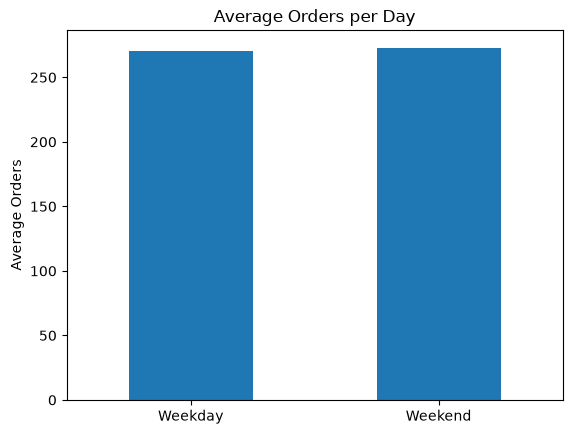

In [26]:
dated_orders = df_raw.dropna(subset=["Order_Date"]).copy()
dated_orders["Order_Date"] = pd.to_datetime(
    dated_orders["Order_Date"],
    format="%m/%d/%Y"
)

daily_counts = (
    dated_orders.groupby(["Order_Date", "Order_Day"])
    .size()
    .reset_index(name="Orders")
)

average_per_day = daily_counts.groupby("Order_Day")["Orders"].mean()
average_per_day = average_per_day.reindex(["Weekday", "Weekend"])

print("Average orders per recorded day:")
print(average_per_day.round(1))

average_per_day.plot(kind="bar", title="Average Orders per Day")
plt.ylabel("Average Orders")
plt.xlabel("")
plt.xticks(rotation=0)
plt.show()

4.4 Distance vs delivery delay relationship


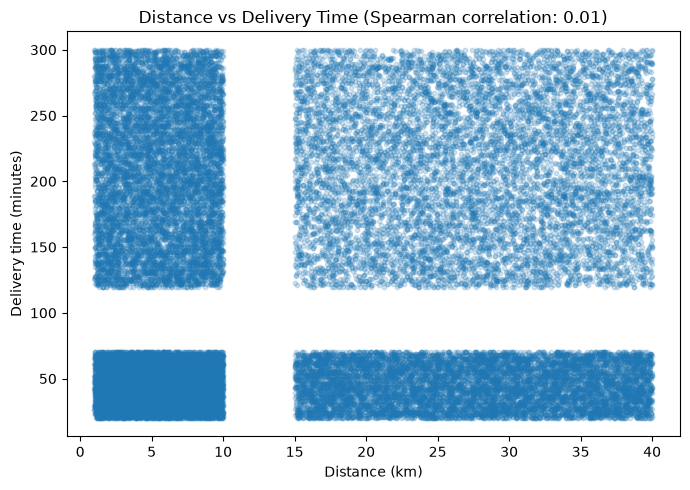

Orders included: 37786
Spearman correlation: 0.007


In [27]:
import matplotlib.pyplot as plt

delivered = df_raw[df_raw["Order_Status"] == "Delivered"]
distance_time = delivered[["Distance_km", "Delivery_Time_Min"]].dropna()

correlation = distance_time.corr(method="spearman").iloc[0, 1]

plt.figure(figsize=(7, 5))
plt.scatter(
    distance_time["Distance_km"],
    distance_time["Delivery_Time_Min"],
    alpha=0.2,
    s=10
)
plt.title(f"Distance vs Delivery Time (Spearman correlation: {correlation:.2f})")
plt.xlabel("Distance (km)")
plt.ylabel("Delivery time (minutes)")
plt.tight_layout()
plt.show()

print("Orders included:", len(distance_time))
print("Spearman correlation:", round(correlation, 3))

4.5 Cancellation reasons analysis


Cancellation reason counts:
Cancellation_Reason
Restaurant Issue      2979
Customer Cancelled    2993
Late Delivery         3059
Unknown               6005
Name: count, dtype: int64


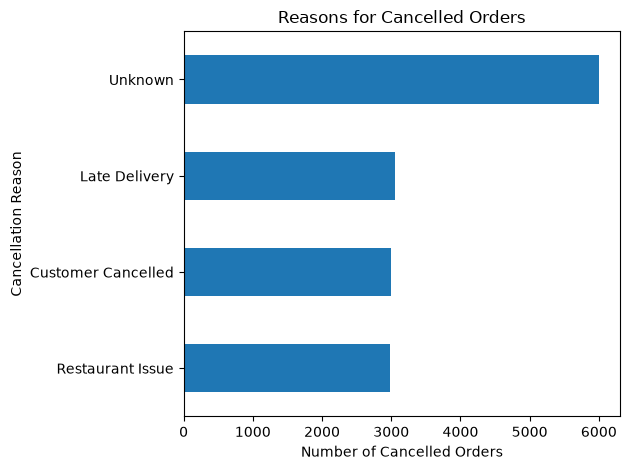

In [28]:
cancelled_orders = df_clean[df_clean["Order_Status"] == "Cancelled"]
reason_counts = cancelled_orders["Cancellation_Reason"].value_counts().sort_values()

print("Cancellation reason counts:")
print(reason_counts)

reason_counts.plot(kind="barh", title="Reasons for Cancelled Orders")
plt.xlabel("Number of Cancelled Orders")
plt.ylabel("Cancellation Reason")
plt.tight_layout()
plt.show()

4.6 Correlation analysis among numeric features


In [29]:
numeric_columns = df_raw.select_dtypes(include="number").columns
correlation_matrix = df_raw[numeric_columns].corr()

display(correlation_matrix.round(2))

,Customer_Age,Delivery_Time_Min,Distance_km,Order_Value,Discount_Applied,Final_Amount,Delivery_Rating,Restaurant_Rating,Profit_Margin
Customer_Age,1.00,-0.02,-0.0,-0.00,0.00,-0.00,-0.0,0.00,0.00
Delivery_Time_Min,-0.02,1.00,0.0,0.00,-0.00,-0.00,0.0,0.00,-0.00
Distance_km,-0.00,0.00,1.0,0.00,0.00,-0.00,0.0,0.00,0.00
Order_Value,-0.00,0.00,0.0,1.00,0.00,1.00,-0.0,-0.01,-0.00
Discount_Applied,0.00,-0.00,0.0,0.00,1.00,-0.07,0.0,0.00,0.01
Final_Amount,-0.00,-0.00,-0.0,1.00,-0.07,1.00,-0.0,-0.01,-0.01
Delivery_Rating,-0.00,0.00,0.0,-0.00,0.00,-0.00,1.0,0.00,0.00
Restaurant_Rating,0.00,0.00,0.0,-0.01,0.00,-0.01,0.0,1.00,-0.00
Profit_Margin,0.00,-0.00,0.0,-0.00,0.01,-0.01,0.0,-0.00,1.00


Step 5: Feature Engineering

5.1 Order day type(Weekday/Weekend)

In [31]:
print("Order day categories:")
print(df_clean["Order_Day"].value_counts(dropna=False))


Order day categories:
Order_Day
Weekday    71370
Weekend    28630
Name: count, dtype: int64


5.2 Peak hour indicator

In [ ]:
print("\nPeak hour values:")
print(df_clean["Peak_Hour"].value_counts(dropna=False))


Peak hour values:
Peak_Hour
False    66547
True     33453
Name: count, dtype: int64


5.3 Profit margin percentage

In [33]:
print("\nProfit margin summary:")
print(df_clean["Profit_Margin"].describe())


Profit margin summary:
count    100000.000000
mean          0.150362
std           0.201888
min          -0.200000
25%          -0.020000
50%           0.150000
75%           0.320000
max           0.500000
Name: Profit_Margin, dtype: float64


In [37]:
df_clean["Profit_Margin_Percent"] = df_clean["Profit_Margin"] * 100

print("Profit margin percentage summary:")
print(df_clean["Profit_Margin_Percent"].describe().round(2))

Profit margin percentage summary:
count    100000.00
mean         15.04
std          20.19
min         -20.00
25%          -2.00
50%          15.00
75%          32.00
max          50.00
Name: Profit_Margin_Percent, dtype: float64


5.4 Delivery performance categories

In [34]:
print("\nDelivery time summary by order status:")
print(df_clean.groupby("Order_Status")["Delivery_Time_Min"].describe())


Delivery time summary by order status:
                count        mean        std   min   25%    50%    75%    max
Order_Status                                                                 
Cancelled     15036.0  125.010442  73.916693  20.0  58.0  120.0  164.0  300.0
Delivered     84964.0  124.977002  74.264519  20.0  58.0  120.0  165.0  300.0


In [38]:
# Use recorded times for delivered orders to calculate data-based cutoffs
delivered = df_raw["Order_Status"] == "Delivered"
observed_delivered = delivered & df_raw["Delivery_Time_Min"].notna()

q1 = df_raw.loc[observed_delivered, "Delivery_Time_Min"].quantile(0.25)
q3 = df_raw.loc[observed_delivered, "Delivery_Time_Min"].quantile(0.75)

# Start by keeping cancelled orders separate
df_clean["Delivery_Performance"] = "Cancelled / not delivered"

# Delivered orders without a recorded time stay identifiable
df_clean.loc[delivered, "Delivery_Performance"] = "No recorded time"

# Categorize delivered orders using their original recorded times
shorter = observed_delivered & (df_raw["Delivery_Time_Min"] <= q1)
typical = (
    observed_delivered
    & (df_raw["Delivery_Time_Min"] > q1)
    & (df_raw["Delivery_Time_Min"] <= q3)
)
longer = observed_delivered & (df_raw["Delivery_Time_Min"] > q3)

df_clean.loc[shorter, "Delivery_Performance"] = "Shorter"
df_clean.loc[typical, "Delivery_Performance"] = "Typical"
df_clean.loc[longer, "Delivery_Performance"] = "Longer"

print(f"Shorter cutoff (25th percentile): {q1:.1f} minutes")
print(f"Longer cutoff (75th percentile): {q3:.1f} minutes")
print("\nDelivery performance categories:")
print(df_clean["Delivery_Performance"].value_counts())

Shorter cutoff (25th percentile): 45.0 minutes
Longer cutoff (75th percentile): 210.0 minutes

Delivery performance categories:
Delivery_Performance
No recorded time             28329
Typical                      28072
Cancelled / not delivered    15036
Shorter                      14503
Longer                       14060
Name: count, dtype: int64


5.5 Customer age groups

In [ ]:
# Mark ages that were missing in the original data
age_missing_in_source = df_raw["Customer_Age"].isna()

# Group the cleaned ages
age_groups = pd.cut(
    df_clean["Customer_Age"],
    bins=[0, 17, 29, 44, 59, float("inf")],
    labels=["17 or younger", "18-29", "30-44", "45-59", "60+"],
    include_lowest=True
)

df_clean["Customer_Age_Group"] = age_groups.astype("object")

# Keep originally missing ages separate from imputed ages
df_clean.loc[age_missing_in_source, "Customer_Age_Group"] = "Age not recorded"

print(df_clean["Customer_Age_Group"].value_counts(dropna=False))

Customer_Age_Group
Age not recorded    50093
30–44               17450
45–59               17431
18–29               13910
60+                  1116
Name: count, dtype: int64


Again Converting the CSV file, done after EDA & Feature engineering to save in SQL and perfrom queries

In [39]:
df_clean.to_csv("online_food_delivery_with_features.csv", index=False)
print("File saved!")

File saved!


Step 6: Data Storage(MySQL)

6.1 Cleaned data can be stored in MySQL

In [41]:
from sqlalchemy import create_engine, URL

connection_url = URL.create(
    "mysql+pymysql",
    username="root",
    password=1234,
    host="localhost",
    port=3306,
    database="online_food_delivery_analysis"
)

engine = create_engine(connection_url)

with engine.connect():
    print("Connected to MySQL successfully!")

Connected to MySQL successfully!


6.2 Table creation with proper data types


In [42]:
import pandas as pd
from sqlalchemy import String, Integer, Float, Boolean, Date, Time

data = pd.read_csv(
    r"C:\Users\Admin\Project\Online Food Delivery Analysis\online_food_delivery_with_features.csv"
)

data["Order_Date"] = pd.to_datetime(
    data["Order_Date"], format="%m/%d/%Y", errors="coerce"
).dt.date

data["Order_Time"] = pd.to_datetime(
    data["Order_Time"], format="mixed", errors="coerce"
).dt.time

sql_types = {}

text_columns = [
    "Order_ID", "Customer_ID", "Customer_Gender", "City", "Area",
    "Restaurant_ID", "Restaurant_Name", "Cuisine_Type", "Payment_Mode",
    "Order_Status", "Cancellation_Reason", "Delivery_Partner_ID",
    "Order_Day", "Customer_Age_Group", "Delivery_Performance"
]

number_columns = [
    "Distance_km", "Order_Value", "Discount_Applied", "Final_Amount",
    "Delivery_Rating", "Restaurant_Rating", "Profit_Margin",
    "Profit_Margin_Percent"
]

for column in text_columns:
    sql_types[column] = String(100)

for column in number_columns:
    sql_types[column] = Float()

sql_types["Customer_Age"] = Integer()
sql_types["Delivery_Time_Min"] = Integer()
sql_types["Peak_Hour"] = Boolean()
sql_types["Order_Date"] = Date()
sql_types["Order_Time"] = Time()

6.3 Data inserted using SQLAlchemy

In [43]:
data.to_sql(
    "orders",
    con=engine,
    index=False,
    dtype=sql_types,
    chunksize=1000
)

print("Rows uploaded:", len(data))

Rows uploaded: 100000


6.4 Enables scalable querying and reporting

In [44]:
from sqlalchemy import text

with engine.connect() as connection:
    total = connection.execute(
        text("SELECT COUNT(*) FROM orders")
    ).scalar_one()

print("Total rows in orders:", total)

Total rows in orders: 100000


In [45]:
query = """
SELECT Order_Status, COUNT(*) AS Order_Count
FROM orders
GROUP BY Order_Status
ORDER BY Order_Count DESC;
"""

status_summary = pd.read_sql_query(query, engine)
display(status_summary)

,Order_Status,Order_Count
0,Delivered,84964
1,Cancelled,15036


In [46]:
query = """
SELECT Cancellation_Reason, COUNT(*) AS Cancelled_Orders
FROM orders
WHERE Order_Status = 'Cancelled'
GROUP BY Cancellation_Reason
ORDER BY Cancelled_Orders DESC;
"""

cancellation_summary = pd.read_sql_query(query, engine)
display(cancellation_summary)

,Cancellation_Reason,Cancelled_Orders
0,Unknown,6005
1,Late Delivery,3059
2,Customer Cancelled,2993
3,Restaurant Issue,2979


## Analyst Tasks (EDA & Analytics)


Customer & Order Analysis

1. Identify top-spending customers

In [47]:
query = """
SELECT
    Customer_ID,
    COUNT(*) AS Delivered_Orders,
    ROUND(SUM(Final_Amount), 2) AS Total_Spent
FROM orders
WHERE Order_Status = 'Delivered'
GROUP BY Customer_ID
ORDER BY Total_Spent DESC
LIMIT 10;
"""

top_customers = pd.read_sql_query(query, engine)
display(top_customers)

,Customer_ID,Delivered_Orders,Total_Spent
0,CUST5267,19,48627.0
1,CUST6706,18,47389.0
2,CUST1606,18,43715.0
3,CUST5534,18,43303.0
4,CUST1239,18,42869.0
5,CUST5180,18,42200.0
6,CUST8524,15,41582.0
7,CUST6252,18,41051.0
8,CUST5530,19,40734.0
9,CUST3471,19,40683.0


2. Analyze age group vs order value


In [48]:
query = """
SELECT
    Customer_Age_Group,
    COUNT(*) AS Delivered_Orders,
    ROUND(AVG(Order_Value), 2) AS Average_Order_Value
FROM orders
WHERE Order_Status = 'Delivered'
GROUP BY Customer_Age_Group
ORDER BY Average_Order_Value DESC;
"""

age_order_summary = pd.read_sql_query(query, engine)
display(age_order_summary)

,Customer_Age_Group,Delivered_Orders,Average_Order_Value
0,45–59,14778,1798.46
1,18–29,11869,1793.78
2,30–44,14836,1784.96
3,Age not recorded,42528,1784.15
4,60+,953,1755.65


3. Weekend vs weekday order patterns


In [49]:
query = """
SELECT
    Order_Day,
    COUNT(*) AS Total_Orders,
    COUNT(DISTINCT Order_Date) AS Recorded_Days,
    ROUND(COUNT(*) / COUNT(DISTINCT Order_Date), 1) AS Average_Orders_Per_Day
FROM orders
WHERE Order_Date IS NOT NULL
GROUP BY Order_Day
ORDER BY Average_Orders_Per_Day DESC;
"""

day_pattern = pd.read_sql_query(query, engine)
display(day_pattern)

,Order_Day,Total_Orders,Recorded_Days,Average_Orders_Per_Day
0,Weekend,28368,104,272.8
1,Weekday,70618,261,270.6


Revenue & Profit Analysis


4. Monthly revenue trends


In [51]:
query = """
SELECT
    DATE_FORMAT(Order_Date, '%%Y-%%m') AS Order_Month,
    COUNT(*) AS Delivered_Orders,
    ROUND(SUM(Final_Amount), 2) AS Revenue
FROM orders
WHERE Order_Status = 'Delivered'
  AND Order_Date IS NOT NULL
GROUP BY DATE_FORMAT(Order_Date, '%%Y-%%m')
ORDER BY Order_Month;
"""

monthly_revenue = pd.read_sql_query(query, engine)
display(monthly_revenue)

,Order_Month,Delivered_Orders,Revenue
0,2024-01,7179,12250578.0
1,2024-02,6748,11439957.0
2,2024-03,7138,12044051.0
3,2024-04,6886,11642842.0
4,2024-05,7124,12235290.0
5,2024-06,6907,11835035.0
6,2024-07,7244,12477095.0
7,2024-08,7039,11953119.0
8,2024-09,6972,11969709.0
9,2024-10,7000,11753576.0


5. Impact of discounts on profit


In [52]:
query = """
SELECT
    CASE
        WHEN Discount_Applied > 0 THEN 'Discount applied'
        ELSE 'No discount'
    END AS Discount_Group,
    COUNT(*) AS Delivered_Orders,
    ROUND(AVG(Discount_Applied), 2) AS Average_Discount,
    ROUND(AVG(Profit_Margin_Percent), 2) AS Average_Profit_Margin_Percent
FROM orders
WHERE Order_Status = 'Delivered'
GROUP BY Discount_Group
ORDER BY Average_Profit_Margin_Percent DESC;
"""

discount_profit = pd.read_sql_query(query, engine)
display(discount_profit)

,Discount_Group,Delivered_Orders,Average_Discount,Average_Profit_Margin_Percent
0,Discount applied,70728,103.92,15.00
1,No discount,14236,0.00,14.98


6. High-revenue cities and cuisines

In [53]:
city_query = """
SELECT
    City,
    COUNT(*) AS Delivered_Orders,
    ROUND(SUM(Final_Amount), 2) AS Revenue
FROM orders
WHERE Order_Status = 'Delivered'
GROUP BY City
ORDER BY Revenue DESC;
"""

cuisine_query = """
SELECT
    Cuisine_Type,
    COUNT(*) AS Delivered_Orders,
    ROUND(SUM(Final_Amount), 2) AS Revenue
FROM orders
WHERE Order_Status = 'Delivered'
GROUP BY Cuisine_Type
ORDER BY Revenue DESC;
"""

city_revenue = pd.read_sql_query(city_query, engine)
cuisine_revenue = pd.read_sql_query(cuisine_query, engine)

print("Revenue by city")
display(city_revenue)

print("Revenue by cuisine")
display(cuisine_revenue)

Revenue by city


,City,Delivered_Orders,Revenue
0,Hyderabad,28532,48408443.0
1,Bangalore,14231,24374658.0
2,Delhi,14181,24025164.0
3,Chennai,13988,23882113.0
4,Mumbai,14032,23858726.0


Revenue by cuisine


,Cuisine_Type,Delivered_Orders,Revenue
0,Indian,28473,48666826.0
1,Chinese,14173,24179758.0
2,Mexican,14090,24159190.0
3,Arabian,14200,23855460.0
4,Italian,14028,23687870.0


Delivery Performance


7. Average delivery time by city


In [54]:
query = """
SELECT
    City,
    COUNT(*) AS Delivered_Orders,
    ROUND(AVG(Delivery_Time_Min), 1) AS Average_Delivery_Minutes
FROM orders
WHERE Order_Status = 'Delivered'
GROUP BY City
ORDER BY Average_Delivery_Minutes;
"""

delivery_by_city = pd.read_sql_query(query, engine)
display(delivery_by_city)

,City,Delivered_Orders,Average_Delivery_Minutes
0,Chennai,13988,124.3
1,Bangalore,14231,124.3
2,Delhi,14181,125.0
3,Hyderabad,28532,125.2
4,Mumbai,14032,125.8


8. Distance vs delivery delay analysis


In [ ]:
query = """
SELECT
    CASE
        WHEN Distance_km <= 5 THEN '0-5 km'
        WHEN Distance_km <= 10 THEN 'Over 5-10 km'
        WHEN Distance_km <= 20 THEN 'Over 10-20 km'
        ELSE 'Over 20 km'
    END AS Distance_Band,
    COUNT(*) AS Delivered_Orders,
    ROUND(AVG(Delivery_Time_Min), 1) AS Average_Delivery_Minutes
FROM orders
WHERE Order_Status = 'Delivered'
GROUP BY Distance_Band
ORDER BY MIN(Distance_km);
"""

distance_delivery = pd.read_sql_query(query, engine)
display(distance_delivery)

,Distance_Band,Delivered_Orders,Average_Delivery_Minutes
0,0–5 km,12655,124.2
1,Over 5–10 km,44096,124.8
2,Over 10–20 km,5675,125.7
3,Over 20 km,22538,125.6


9. Delivery rating vs delivery time


In [56]:
query = """
SELECT
    Delivery_Performance,
    COUNT(*) AS Delivered_Orders,
    ROUND(AVG(Delivery_Time_Min), 1) AS Average_Delivery_Minutes,
    ROUND(AVG(Delivery_Rating), 2) AS Average_Delivery_Rating
FROM orders
WHERE Order_Status = 'Delivered'
  AND Delivery_Performance IN ('Shorter', 'Typical', 'Longer')
GROUP BY Delivery_Performance
ORDER BY Average_Delivery_Minutes;
"""

rating_time_summary = pd.read_sql_query(query, engine)
display(rating_time_summary)

,Delivery_Performance,Delivered_Orders,Average_Delivery_Minutes,Average_Delivery_Rating
0,Shorter,14503,32.5,2.98
1,Typical,28072,112.5,3.00
2,Longer,14060,255.3,3.01


Restaurant Performance


10. Top-rated restaurants


In [57]:
query = """
SELECT
    Restaurant_ID,
    Restaurant_Name,
    COUNT(*) AS Delivered_Orders,
    ROUND(AVG(Restaurant_Rating), 2) AS Average_Rating
FROM orders
WHERE Order_Status = 'Delivered'
  AND Restaurant_Rating IS NOT NULL
GROUP BY Restaurant_ID, Restaurant_Name
ORDER BY Average_Rating DESC, Delivered_Orders DESC
LIMIT 10;
"""

top_restaurants = pd.read_sql_query(query, engine)
display(top_restaurants)

,Restaurant_ID,Restaurant_Name,Delivered_Orders,Average_Rating
0,RES530,Restaurant_177,3,5.0
1,RES795,Restaurant_124,3,5.0
2,RES924,Restaurant_370,3,5.0
3,RES177,Restaurant_173,3,5.0
4,RES676,Restaurant_140,3,5.0
5,RES756,Restaurant_123,3,5.0
6,RES779,Restaurant_43,2,5.0
7,RES816,Restaurant_446,2,5.0
8,RES977,Restaurant_359,2,5.0
9,RES133,Restaurant_321,2,5.0


11. Cancellation rate by restaurant

In [58]:
query = """
SELECT
    Restaurant_ID,
    Restaurant_Name,
    COUNT(*) AS Total_Orders,
    SUM(CASE WHEN Order_Status = 'Cancelled' THEN 1 ELSE 0 END) AS Cancelled_Orders,
    ROUND(
        100.0 * SUM(CASE WHEN Order_Status = 'Cancelled' THEN 1 ELSE 0 END) / COUNT(*),
        2
    ) AS Cancellation_Rate_Percent
FROM orders
GROUP BY Restaurant_ID, Restaurant_Name
ORDER BY Cancellation_Rate_Percent DESC;
"""

restaurant_cancellations = pd.read_sql_query(query, engine)
display(restaurant_cancellations)

,Restaurant_ID,Restaurant_Name,Total_Orders,Cancelled_Orders,Cancellation_Rate_Percent
0,RES792,Restaurant_487,1,1.0,100.0
1,RES269,Restaurant_76,1,1.0,100.0
2,RES535,Restaurant_225,1,1.0,100.0
3,RES778,Restaurant_376,1,1.0,100.0
4,RES268,Restaurant_10,1,1.0,100.0
...,...,...,...,...,...
89548,RES561,Restaurant_120,1,0.0,0.0
89549,RES436,Restaurant_316,1,0.0,0.0
89550,RES980,Restaurant_238,1,0.0,0.0
89551,RES466,Restaurant_293,2,0.0,0.0


12. Cuisine-wise performance

In [59]:
query = """
SELECT
    Cuisine_Type,
    COUNT(*) AS Total_Orders,
    SUM(CASE WHEN Order_Status = 'Delivered' THEN 1 ELSE 0 END) AS Delivered_Orders,
    ROUND(
        100.0 * SUM(CASE WHEN Order_Status = 'Cancelled' THEN 1 ELSE 0 END) / COUNT(*),
        2
    ) AS Cancellation_Rate_Percent,
    ROUND(
        SUM(CASE WHEN Order_Status = 'Delivered' THEN Final_Amount ELSE 0 END),
        2
    ) AS Delivered_Revenue,
    ROUND(
        AVG(CASE WHEN Order_Status = 'Delivered' THEN Delivery_Time_Min END),
        1
    ) AS Average_Delivery_Minutes,
    ROUND(
        AVG(CASE WHEN Order_Status = 'Delivered' THEN Restaurant_Rating END),
        2
    ) AS Average_Restaurant_Rating
FROM orders
GROUP BY Cuisine_Type
ORDER BY Delivered_Revenue DESC;
"""

cuisine_performance = pd.read_sql_query(query, engine)
display(cuisine_performance)

,Cuisine_Type,Total_Orders,Delivered_Orders,Cancellation_Rate_Percent,Delivered_Revenue,Average_Delivery_Minutes,Average_Restaurant_Rating
0,Indian,33570,28473.0,15.18,48666826.0,125.3,4.20
1,Chinese,16651,14173.0,14.88,24179758.0,123.7,4.19
2,Mexican,16602,14090.0,15.13,24159190.0,125.2,4.20
3,Arabian,16658,14200.0,14.76,23855460.0,125.1,4.21
4,Italian,16519,14028.0,15.08,23687870.0,125.2,4.21


Operational Insights

13. Peak hour demand analysis


In [60]:
query = """
SELECT
    CASE
        WHEN Peak_Hour = 1 THEN 'Peak Hour'
        ELSE 'Off-Peak'
    END AS Period,
    COUNT(*) AS Total_Orders,
    ROUND(
        100.0 * COUNT(*) / (SELECT COUNT(*) FROM orders),
        2
    ) AS Percent_Of_Orders
FROM orders
GROUP BY
    CASE
        WHEN Peak_Hour = 1 THEN 'Peak Hour'
        ELSE 'Off-Peak'
    END;
"""

peak_demand = pd.read_sql_query(query, engine)
display(peak_demand)

,Period,Total_Orders,Percent_Of_Orders
0,Peak Hour,33453,33.45
1,Off-Peak,66547,66.55


14. Payment mode preferences


In [61]:
query = """
SELECT
    Payment_Mode,
    COUNT(*) AS Total_Orders,
    ROUND(
        100.0 * COUNT(*) / (SELECT COUNT(*) FROM orders),
        2
    ) AS Percent_Of_Orders
FROM orders
GROUP BY Payment_Mode
ORDER BY Total_Orders DESC;
"""

payment_preferences = pd.read_sql_query(query, engine)
display(payment_preferences)

,Payment_Mode,Total_Orders,Percent_Of_Orders
0,Card,40005,40.01
1,Wallet,20086,20.09
2,COD,19977,19.98
3,UPI,19932,19.93


15. Cancellation reason analysis


In [62]:
query = """
SELECT
    Cancellation_Reason,
    COUNT(*) AS Cancelled_Orders,
    ROUND(
        100.0 * COUNT(*) /
        (SELECT COUNT(*) FROM orders WHERE Order_Status = 'Cancelled'),
        2
    ) AS Percent_Of_Cancellations
FROM orders
WHERE Order_Status = 'Cancelled'
GROUP BY Cancellation_Reason
ORDER BY Cancelled_Orders DESC;
"""

cancellation_analysis = pd.read_sql_query(query, engine)
display(cancellation_analysis)

,Cancellation_Reason,Cancelled_Orders,Percent_Of_Cancellations
0,Unknown,6005,39.94
1,Late Delivery,3059,20.34
2,Customer Cancelled,2993,19.91
3,Restaurant Issue,2979,19.81
